| $L$ | Expected $2^L$ | Measured | Match |
|---|---|---|---|
| 1 | 2 | 2 | yes |
| 2 | 4 | 4 | yes |
| 4 | 16 | 16 | yes |
| 6 | 64 | 64 | yes |
| 8 | 256 | 256 | yes |
| 10 | 1024 | 1024 | yes |
| 12 | 4096 | 4096 | yes |


MLP (3 layers) run 5/5: 100%|██████████| 10000/10000 [00:02<00:00, 3984.27it/s, loss=0.0377]


saved results\test3_affine_pieces.png
saved results\test3_affine_pieces.pdf


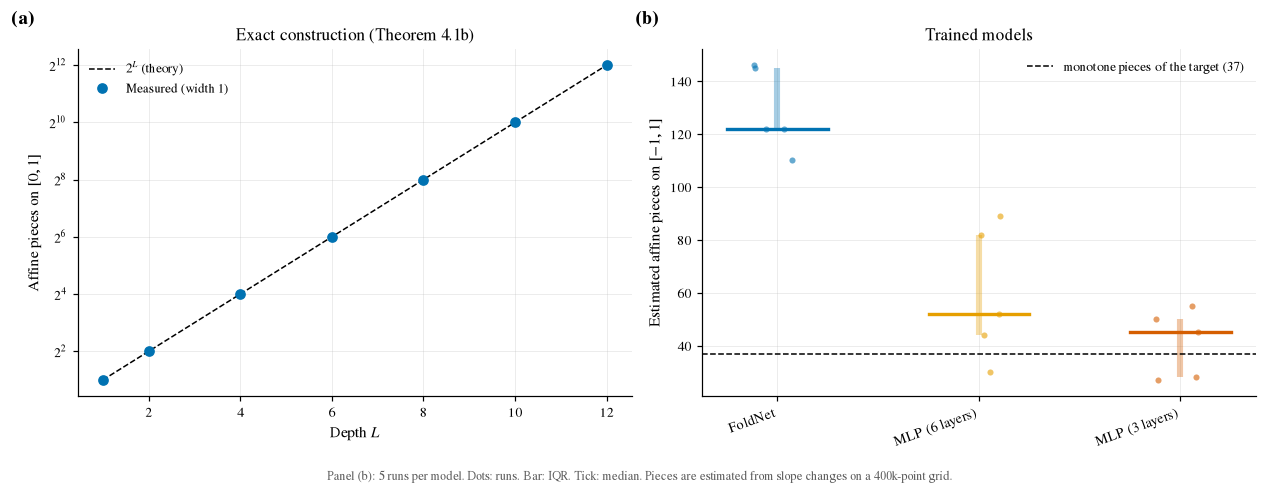

| Model | Params | Estimated pieces | Test MSE |
|---|---|---|---|
| FoldNet | 673 | 122 [122, 145] | 2.84e-02 [2.13e-02, 3.02e-02] |
| MLP (6 layers) | 694 | 52 [44, 82] | 1.85e-01 [4.95e-02, 2.28e-01] |
| MLP (3 layers) | 664 | 45 [28, 50] | 6.58e-02 [5.65e-02, 2.08e-01] |
saved results\test3_construction_table.{md,tex,csv}
saved results\test3_trained_table.{md,tex,csv}


In [ ]:
"""Test 3: number of affine pieces. Exact construction (Theorem 4.1b) and trained models."""
import numpy as np
import torch
import matplotlib.pyplot as plt

from foldnet_lib import FoldNet, DEV
from foldnet_bench import standard_builders, benchmark
import foldnet_viz as V

LS = [1, 2, 4, 6, 8, 10, 12]      # depths for the exact construction
N_RUNS = 5
STEPS = 10000
D, DEPTH, K = 32, 6, 2
USE = ["FoldNet", "MLP (6 layers)", "MLP (3 layers)"]
RESULTS_DIR = "results"


def f(x):
    return torch.sin(20 * x) + 0.5 * torch.sin(55 * x)


def build_theoretical(L, k=2):
    """Width-1 FoldNet with 2^L affine pieces on [0, 1], in float64 for exact counting."""
    m = FoldNet(1, 1, d=1, depth=L, k=k).to(DEV).double()  # <-- float64 crucial
    with torch.no_grad():
        m.inp.weight.fill_(1.0)
        m.inp.bias.zero_()
        m.out.weight.fill_(2.0 ** L)
        m.out.bias.zero_()
        for l in range(L):
            m.v[l].fill_(1.0)
            m.t[l].fill_((-1) ** k * 2.0 ** (-(l + 1)))
    return m


def count_pieces(model, lo, hi, n=400_000, rel=1e-3):
    """Estimate by counting slope changes on a grid. The grid is shifted by an irrational
    fraction of a cell so that no point falls exactly on a dyadic kink."""
    h = (hi - lo) / n
    # <-- ajout de .unsqueeze(1) pour passer de [n] à [n, 1]
    x = (lo + h * (torch.arange(n, device=DEV, dtype=torch.float64) + 0.381966)).unsqueeze(1)
    x = x.requires_grad_(True)
    
    g = torch.autograd.grad(model(x).sum(), x)[0].squeeze(1).detach().cpu().numpy()
    
    thr = rel * max(np.abs(g).max(), 1e-12)
    return int((np.abs(np.diff(g)) > thr).sum()) + 1


if __name__ == "__main__":
    torch.backends.cuda.matmul.allow_tf32 = False   # exact kinks need full precision
    V.set_style()

    # (a) Exact construction
    measured = [count_pieces(build_theoretical(L, K), 0.0, 1.0) for L in LS]
    tab1 = V.Table(["$L$", "Expected $2^L$", "Measured", "Match"])
    for L, mval in zip(LS, measured):
        tab1.add(L, 2 ** L, mval, "yes" if mval == 2 ** L else "NO")
    tab1.show()

    # (b) Trained models
    all_b, target = standard_builders(1, 1, D, DEPTH, K)
    builders = {n: all_b[n] for n in USE}
    res, xs, ys = benchmark(builders, f, n_runs=N_RUNS, steps=STEPS, keep_models=True)
    
    # On passe les modèles entraînés en float64 le temps du comptage
    pieces = {}
    for n in USE:
        pieces[n] = np.array([
            count_pieces(r["model"].double(), -1.0, 1.0) for r in res[n]
        ])
    
    mse = {n: np.array([r["mse"] for r in res[n]]) for n in USE}
    npar = {n: res[n][0]["n_params"] for n in USE}

    # Calcul des pièces monotones de la cible
    xg = np.linspace(-1, 1, 200001)
    dfx = 20 * np.cos(20 * xg) + 27.5 * np.cos(55 * xg)
    min_pieces = int((np.diff(np.sign(dfx)) != 0).sum()) + 1

    # --- Figure ---
    fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.3))
    
    ax = axes[0]
    Lf = np.linspace(min(LS), max(LS), 100)
    ax.plot(Lf, 2.0 ** Lf, "k--", lw=1, label=r"$2^L$ (theory)")
    ax.plot(LS, measured, "o", color=V.color_for("FoldNet"), ms=6, label="Measured (width 1)")
    ax.set_yscale("log", base=2)
    ax.set_xlabel("Depth $L$")
    ax.set_ylabel("Affine pieces on $[0,1]$")
    ax.set_title("Exact construction (Theorem 4.1b)")
    ax.legend()
    V.panel_label(ax, "(a)")

    ax = axes[1]
    V.strip(ax, USE, [pieces[n] for n in USE], {n: V.color_for(n) for n in USE})
    ax.axhline(min_pieces, color="k", ls="--", lw=1,
               label=f"monotone pieces of the target ({min_pieces})")
    ax.set_ylabel("Estimated affine pieces on $[-1,1]$")
    ax.set_title("Trained models")
    ax.legend()
    V.panel_label(ax, "(b)")

    fig.text(0.5, -0.03, f"Panel (b): {N_RUNS} runs per model. Dots: runs. Bar: IQR. Tick: median. "
             "Pieces are estimated from slope changes on a 400k-point grid.",
             ha="center", fontsize=8, color="0.35")
    plt.tight_layout()
    V.savefig(fig, "test3_affine_pieces", RESULTS_DIR)
    plt.show()

    # --- Tables ---
    tab2 = V.Table(["Model", "Params", "Estimated pieces", "Test MSE"])
    for n in USE:
        tab2.add(n, npar[n], V.med_iqr(pieces[n], lambda v: f"{v:.0f}"), V.med_iqr(mse[n]))
    tab2.show()

    tab1.save("test3_construction_table", RESULTS_DIR,
              caption="Affine pieces of the width-1 FoldNet of Theorem 4.1(b).", 
              label="tab:construction")
    tab2.save("test3_trained_table", RESULTS_DIR,
              caption=f"Estimated affine pieces of trained models ({N_RUNS} runs), median [Q1, Q3].",
              label="tab:pieces")